Linear Regression 2
---
<b>Summary</b>  
This notebook has a multi-linear regression with the target variable being InterestRate. The regression coeff are near zero, and the R-squared and adjusted R-squared are also near zero indicating that the model does not predict any better than if we were using the mean of the dataset for prediction. Under further investigation, based off of binning credit score into similar groups, the interest rate was not affected indicating there is no relation between variables. When investigating the correlations, the correlations between variables was very low as well.

Overall, a linear regression is not well-suited for predicting interest rate for this dataset.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [13]:
df = pd.read_csv('../Loan_default.csv')
df

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


In [14]:
# decided to remove LoanID because I did not think it was needed
df.drop(columns='LoanID', inplace=True)

In [15]:
# converting features that are binary outcomes (yes and no) to 0 and 1
df[['HasMortgage', 'HasDependents', 'HasCoSigner']] = df[['HasMortgage', 'HasDependents', 'HasCoSigner']].replace({'Yes': 1, 'No': 0}).astype(int)
df

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,1,1,Other,1,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,0,0,Other,1,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,1,1,Auto,0,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,0,0,Business,0,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,0,1,Auto,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,0,0,Other,0,0
255343,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,0,0,Home,0,1
255344,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,1,1,Auto,1,0
255345,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,1,1,Other,0,0


In [16]:
def get_numerics_cats(df, col_names):
    numeric = []
    categorical = []
    for col_name in col_names:
        if pd.api.types.is_numeric_dtype(df[col_name]):
            numeric.append(col_name)
        else: 
            categorical.append(col_name)
    return numeric, categorical

I think for predicting a numeric variable and not default, will look at 
- LoanAmount
- InterestRate
- CreditScore?

In [17]:
y = df['InterestRate']

# drop Default because we would not have that info 
# when predicting the interest rate
x = df.drop(columns=['InterestRate', 'Default'])  

x


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
0,56,85994,50587,520,80,4,36,0.44,Bachelor's,Full-time,Divorced,1,1,Other,1
1,69,50432,124440,458,15,1,60,0.68,Master's,Full-time,Married,0,0,Other,1
2,46,84208,129188,451,26,3,24,0.31,Master's,Unemployed,Divorced,1,1,Auto,0
3,32,31713,44799,743,0,3,24,0.23,High School,Full-time,Married,0,0,Business,0
4,60,20437,9139,633,8,4,48,0.73,Bachelor's,Unemployed,Divorced,0,1,Auto,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,12,0.85,Bachelor's,Full-time,Married,0,0,Other,0
255343,32,51953,189899,511,14,2,24,0.21,High School,Part-time,Divorced,0,0,Home,0
255344,56,84820,208294,597,70,3,60,0.50,High School,Self-employed,Married,1,1,Auto,1
255345,42,85109,60575,809,40,1,48,0.44,High School,Part-time,Single,1,1,Other,0


In [ ]:
col_names = x.columns # get the names of the columns
numeric, categorical = get_numerics_cats(x, col_names)
# separate the columns into numerical and categorical features

display(numeric)
display(categorical)

['Age',
 'Income',
 'LoanAmount',
 'CreditScore',
 'MonthsEmployed',
 'NumCreditLines',
 'LoanTerm',
 'DTIRatio',
 'HasMortgage',
 'HasDependents',
 'HasCoSigner']

['Education', 'EmploymentType', 'MaritalStatus', 'LoanPurpose']

In [ ]:
# split train test
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=123
)

In [ ]:
# create a preprocesser
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(
        drop="first", handle_unknown="ignore"
    ), categorical)
])

In [ ]:
# create a model
linreg =LinearRegression()

# create the pipeline
pipe = Pipeline(steps = [
    ("preprocess", preprocess),
    ("model", linreg)
])

# fit the model
pipe.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Income','LoanAmount',...,'HasDependents','LoanPurpose', 'HasCoSigner']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of co

In [26]:
# get the predictions for the x_test
y_hat = pipe.predict(x_test)

In [27]:
# copy the x test set and store in model_results
model_results = x_test.copy()

# create a new column to store the observed interest rate
model_results["observed_interest_rates"] = y_test

# create a new column to store the predicted interest rates
model_results["predicted_interest_rates"] = y_hat

# create a new col and store the residuals
model_results["residual"] = (
    model_results["observed_interest_rates"]
    -
    model_results["predicted_interest_rates"]
)

model_results.head()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,observed_interest_rates,predicted_interest_rates,residual
81052,32,63892,66362,444,90,3,36,0.27,High School,Full-time,Single,0,1,Education,0,7.45,13.486594,-6.036594
117069,64,41848,177446,693,98,3,36,0.46,High School,Full-time,Single,0,1,Other,0,16.06,13.423308,2.636692
170341,21,103298,111902,689,17,3,24,0.89,Bachelor's,Part-time,Single,0,1,Business,0,23.19,13.460911,9.729089
74885,57,120690,30751,647,46,3,48,0.14,Master's,Unemployed,Single,1,1,Home,1,14.86,13.505546,1.354454
27464,35,137245,176172,585,71,1,12,0.40,Master's,Full-time,Divorced,0,0,Auto,1,12.02,13.470019,-1.450019


In [33]:

print("R-squared", r2_score(y_test, y_hat))
n = len(y_test)
p = len(feature_names)
adjusted_r_squared = (1-(1 - r_squared)*(n - 1)/(n - p - 1))
print(f"Adjusted R²: {adjusted_r_squared}")
print("RMSE", np.sqrt(mean_squared_error(y_test, y_hat)))
print("MAE", mean_absolute_error(y_test, y_hat))

R-squared -3.4734238028022446e-05
Adjusted R²: -0.00048532388045785524
RMSE 6.6450123996803265
MAE 5.751720216113299


In [29]:
fig = px.scatter(
    model_results,
    x="predicted_interest_rates",
    y="residual",
    opacity=0.65,
    title="Residuals Versus Predicted Interest Rates",
    labels={
        "predicted_interest_rates": "Predicted Rates (%)",
        "residual": "Residual: Observed − Predicted",
    },
)

fig.add_hline(
    y=0,
    line_dash="dash",
    line_color="black"
)

fig.show()

In [ ]:
# get the names of the coeffs and store in feature_names
feature_names = (
    pipe
    .named_steps["preprocess"]
    .get_feature_names_out()
)


In [31]:
# create a table to show the coeff on each feature
coefficient_table = pd.DataFrame({
    "predictor": feature_names,
    "coefficient": (
        pipe
        .named_steps["model"]
        .coef_
    )
})

# get the intercept
intercept = (
    pipe
    .named_steps["model"]
    .intercept_
)

print(f"Intercept: {intercept:,.2f}%")

coefficient_table # this is the final model

Intercept: 13.49%


,predictor,coefficient
0,num__Age,-0.002918
1,num__Income,-0.016509
2,num__LoanAmount,-0.021246
3,num__CreditScore,0.009555
4,num__MonthsEmployed,-0.006176
5,num__NumCreditLines,-0.004724
6,num__LoanTerm,0.005668
7,num__DTIRatio,0.000786
8,num__HasMortgage,-0.006416
9,num__HasDependents,-0.007444


In [ ]:
# Compare training and testing performance to see if there
# is a large difference between training r-squared and testing r-squared
train_pred = pipe.predict(x_train)
test_pred = pipe.predict(x_test)

print("Training R²:", r2_score(y_train, train_pred))
print("Testing R²:", r2_score(y_test, test_pred))

# Compare against predicting the training mean
# create something the length of y_test filled with the y_train mean
baseline_pred = np.full(len(y_test), y_train.mean())

# print the RMSE of y-test - mean
print("Baseline RMSE:",
      np.sqrt(mean_squared_error(y_test, baseline_pred)))

# print RMSE of y_test - the test-pred
print("Linear Regression RMSE:",
      np.sqrt(mean_squared_error(y_test, test_pred)))

Training R²: 8.885899195065772e-05
Testing R²: -3.4734238028022446e-05
Baseline RMSE: 6.644976527524465
Linear Regression RMSE: 6.6450123996803265


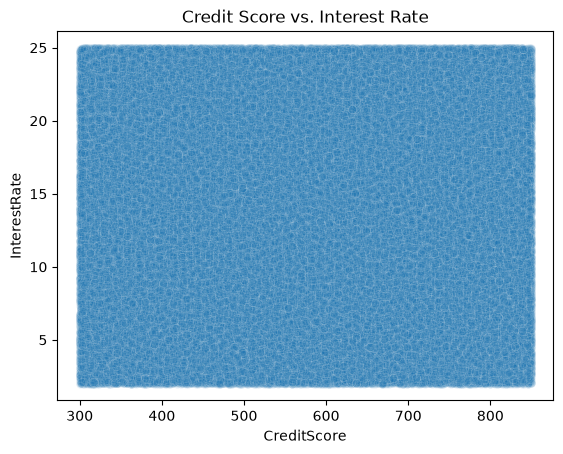

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df,
    x='CreditScore',
    y='InterestRate',
    alpha=0.1
)

plt.title('Credit Score vs. Interest Rate')
plt.show()

In [36]:
df.groupby(
    pd.cut(df['CreditScore'], bins=10),
    observed=True
)['InterestRate'].mean()

CreditScore
(299.451, 354.9]    13.523876
(354.9, 409.8]      13.481105
(409.8, 464.7]      13.510903
(464.7, 519.6]      13.460873
(519.6, 574.5]      13.449143
(574.5, 629.4]      13.460710
(629.4, 684.3]      13.558165
(684.3, 739.2]      13.480061
(739.2, 794.1]      13.472636
(794.1, 849.0]      13.529672
Name: InterestRate, dtype: float64

In [37]:
numeric_df = df.select_dtypes(include='number')

corr = numeric_df.corr()

# Find strongest relationships between numeric variables
corr_pairs = (
    corr.where(
        np.triu(np.ones(corr.shape), k=1).astype(bool)
    )
    .stack()
    .sort_values(key=abs, ascending=False)
)

print(corr_pairs.head(20))

Age             Default          -0.167783
InterestRate    Default           0.131273
Income          Default          -0.099119
MonthsEmployed  Default          -0.097374
LoanAmount      Default           0.086659
HasCoSigner     Default          -0.039109
HasDependents   Default          -0.034678
CreditScore     Default          -0.034166
NumCreditLines  Default           0.028330
HasMortgage     Default          -0.022856
DTIRatio        Default           0.019236
Age             DTIRatio         -0.004689
InterestRate    HasCoSigner      -0.003991
HasMortgage     HasCoSigner      -0.003529
Income          HasCoSigner      -0.003524
CreditScore     HasDependents    -0.003018
Age             HasCoSigner      -0.002918
LoanAmount      MonthsEmployed    0.002817
CreditScore     HasCoSigner      -0.002755
Income          MonthsEmployed    0.002675
dtype: float64
